# Tema 25 · Reutilizar modelos: BERT, codificador-decodificador y ajuste fino

Partir de un modelo que ya sabe mucho y adaptarlo a tu problema con pocos datos.

Este cuaderno es el tema 25 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/25-reutilizar-modelos-bert-codificador-decodificador-y-ajuste-fino/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q accelerate==1.15.0 datasets==5.1.0 peft==0.21.2 transformers==5.21.0 sentencepiece==0.2.2 sacremoses==0.2.0

# Teoría

## La pregunta

Tienes 1500 reseñas de productos, cada una marcada como positiva o negativa, y quieres un programa que clasifique reseñas nuevas. En el tema 21 («Texto como datos») lo hiciste con TF-IDF y regresión logística: funciona, pero solo cuenta palabras. No sabe que «not bad» («nada mal») es casi un elogio ni que «returned it the next day» («lo devolví al día siguiente») es una queja.

Un transformer como los del tema 23 («Atención y transformers») sí podría captar eso, pero entrenarlo desde cero con 1500 textos no alcanza: tendría que aprender el idioma entero (qué palabras existen, cómo se ordenan, qué significan) a partir de unos pocos párrafos. Los modelos que entienden texto de verdad se entrenaron con miles de millones de palabras, durante días, en muchas GPU.

La salida es **no empezar de cero**. Alguien ya entrenó un modelo grande que «sabe leer» y lo publicó con una licencia abierta. Tú lo descargas y lo **ajustas** a tu problema con tus pocos ejemplos, en tu computadora y en minutos. Eso es el **ajuste fino** (*fine-tuning*), y es como se usa hoy la mayor parte de la inteligencia artificial que lee, traduce o describe imágenes.

En este tema vas a:

- distinguir **codificadores**, **decodificadores** y modelos **codificador-decodificador**, y saber para qué sirve cada uno;
- ver cómo se preentrena **BERT** (adivinando palabras tapadas) y para qué sirve su token `[CLS]`;
- ajustar **DistilBERT** para clasificar reseñas de tres maneras: entrenando solo la cabeza, entrenando todo el modelo y con **LoRA**, y comparar la exactitud con el número de parámetros que se entrenan;
- **traducir** con un modelo codificador-decodificador y mirar su **atención cruzada**;
- **describir imágenes** con otro modelo codificador-decodificador;
- ver qué le pasa a un modelo cuando los datos **cambian** (cambio de dominio) o cuando aprende algo nuevo y **olvida** lo viejo, y probar remedios baratos.

Necesitas el bucle de entrenamiento del tema 18, los tokens del tema 21 («Texto como datos»), los embeddings del tema 22 («Embeddings»), el bloque transformer del tema 23 («Atención y transformers») y lo que viste sobre modelos preentrenados en el tema 24 («Modelos de lenguaje»).

Este tema usa `transformers` 5 o más nuevo y la librería `peft` (para LoRA), que Colab no trae. Antes de empezar, ejecuta en una celda aparte `!pip install -U "transformers>=5" peft` y, si ya habías importado `transformers`, reinicia la sesión del cuaderno. Con `import transformers` y `print(transformers.__version__)` compruebas la versión.

## Actividad: rango bajo

LoRA, la técnica estrella de este tema, se apoya en una idea que puedes ver con los ojos. Una foto en blanco y negro de 64 × 64 píxeles es una **matriz** de 4096 números (cada uno, qué tan claro es un píxel). Esa matriz se puede escribir, casi igual, como el producto de dos matrices delgadas: **B**, de 64 filas y *r* columnas, por **A**, de *r* filas y 64 columnas. Guardar B y A cuesta 64·*r*·2 números. El número *r* se llama **rango**.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/25-reutilizar-modelos-bert-codificador-decodificador-y-ajuste-fino/teoria/). Ábrela en el navegador para usarla.
Prueba esto:

1. Empieza con *r* = 1. ¿Qué ves? ¿Por qué salen franjas horizontales y verticales?
2. Sube *r* poco a poco. ¿Desde qué rango reconoces la pagoda? ¿Cuántos números guardas ahí, comparados con 4096?
3. Mira cómo baja el error. ¿Baja igual de rápido al principio que al final?
4. Llega a *r* = 32. ¿Cuántos números guardas? ¿Vale la pena?

Con *r* = 1 la imagen es una sola columna por una sola fila: cada píxel es «lo claro de su fila por lo claro de su columna», y por eso solo hay franjas. Cada rango que sumas agrega un patrón nuevo, y los primeros patrones son los que más ayudan. Con un rango bajo ya está casi todo, guardando una fracción de los números.

LoRA aplica esa idea a los **cambios** que el ajuste fino hace en las matrices de pesos de un modelo: en lugar de cambiar cada uno de los 589 824 números de una matriz de 768 × 768, aprende un cambio de la forma B·A con *r* = 8, que tiene 12 288 números. Al final del tema verás que eso alcanza.

La foto es `china.jpg`, una de las imágenes de ejemplo que trae scikit-learn (de danielbuechele en Flickr, licencia CC BY 2.0), pasada a grises y reducida a 64 × 64.

## Tres familias de transformers

En el tema «Atención y transformers» armaste un bloque transformer y viste que se usa de tres maneras. Ahora vas a usar un modelo real de cada familia:

| Familia | Qué hace | Cada token mira |
|---|---|---|
| **Codificador** (BERT) | entiende un texto entero | a todos |
| **Decodificador** (GPT) | genera, token a token | solo hacia atrás |
| **Codificador-decodificador** (Marian) | transforma una entrada en una salida | también a la entrada (atención cruzada) |

En este tema clasificas reseñas con un codificador (DistilBERT) y traduces y describes imágenes con dos codificadores-decodificadores (Marian y Florence-2). Los decodificadores fueron el tema «Modelos de lenguaje».

La regla práctica: si la tarea es **entender** (clasificar, encontrar, comparar), usa un codificador. Si es **continuar** un texto o conversar, un decodificador. Si es **transformar** una entrada en otra salida (un idioma en otro, una imagen en una frase), un codificador-decodificador.

## BERT: aprender a leer tapando palabras

**BERT** (2018) es un codificador. Se preentrenó con un juego sencillo: se toma un texto, se tapa al azar un 15 % de sus tokens con el token especial `[MASK]` y el modelo tiene que adivinar cuál era cada uno. Eso se llama **modelado de lenguaje enmascarado** (MLM, por sus siglas en inglés). Para adivinar bien, el modelo tiene que usar el contexto de **los dos lados**: en «el gato se subió al [MASK] para dormir», lo que viene después («para dormir») ayuda tanto como lo que viene antes. Por eso un codificador no usa máscara causal.

Lo mejor del juego es que no necesita etiquetas: cualquier texto sirve. BERT se entrenó con libros y con la Wikipedia en inglés, unos 3300 millones de palabras.

Vamos a usar **DistilBERT**, una versión de BERT con la mitad de las capas (6 en lugar de 12) que es un 60 % más rápida y conserva un 97 % del rendimiento de BERT. Viene con su cabeza de MLM, así que puedes jugar al mismo juego con él. Es de Hugging Face, con licencia Apache-2.0, y pesa 268 MB; está en inglés, como las reseñas que vas a clasificar.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

NOMBRE = "distilbert/distilbert-base-uncased"
tokenizador = AutoTokenizer.from_pretrained(NOMBRE)
bert_mlm = AutoModelForMaskedLM.from_pretrained(NOMBRE).to(device).eval()


def completar(frase, k=5):
    """Las k palabras más probables para el [MASK] de la frase."""
    x = tokenizador(frase, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = bert_mlm(**x).logits
    # La posición del [MASK] dentro de la frase tokenizada
    pos = (x["input_ids"][0] == tokenizador.mask_token_id).nonzero()[0, 0]
    probs = logits[0, pos].softmax(dim=-1)
    mejores = probs.topk(k)
    palabras = tokenizador.convert_ids_to_tokens(mejores.indices.tolist())
    return palabras, mejores.values.tolist()


print(tokenizador.convert_ids_to_tokens(
    tokenizador("I loved this book.")["input_ids"]))
for frase in ["I loved this book, it was [MASK].",
              "The cat sat on the [MASK].",
              "The capital of France is [MASK]."]:
    palabras, probs = completar(frase)
    print(frase)
    print(" ", ", ".join(f"{p} {q:.2f}" for p, q in zip(palabras, probs)))

['[CLS]', 'i', 'loved', 'this', 'book', '.', '[SEP]']
I loved this book, it was [MASK].
  amazing 0.17, incredible 0.06, wonderful 0.04, beautiful 0.03, fantastic 0.03
The cat sat on the [MASK].
  sofa 0.13, couch 0.12, floor 0.07, bench 0.06, ground 0.04
The capital of France is [MASK].
  marseille 0.14, nantes 0.09, toulouse 0.09, paris 0.09, lyon 0.08


Tres cosas para notar:

- Las frases dicen «Me encantó este libro, fue [MASK]», «El gato se sentó en el [MASK]» y «La capital de Francia es [MASK]». Las respuestas, en el mismo orden: «increíble», «maravilloso», «hermoso» y «fantástico» para la primera; «sofá», «piso», «banca» y «suelo» para la segunda; y ciudades de Francia para la tercera.
- El tokenizador (`uncased`: pasa todo a minúsculas) agrega dos tokens especiales: `[CLS]` al principio y `[SEP]` al final. Ya los viste en el tema 21.
- Las palabras propuestas encajan con la gramática y el sentido de la frase: después de «I loved this book, it was» van elogios.
- En la tercera frase, «paris» sale cuarta. El modelo aprendió que ahí va una ciudad francesa, pero **no es una base de datos de hechos**: predice palabras plausibles, igual que los modelos del tema 24. Un modelo más grande habría acertado más, pero el riesgo es el mismo.

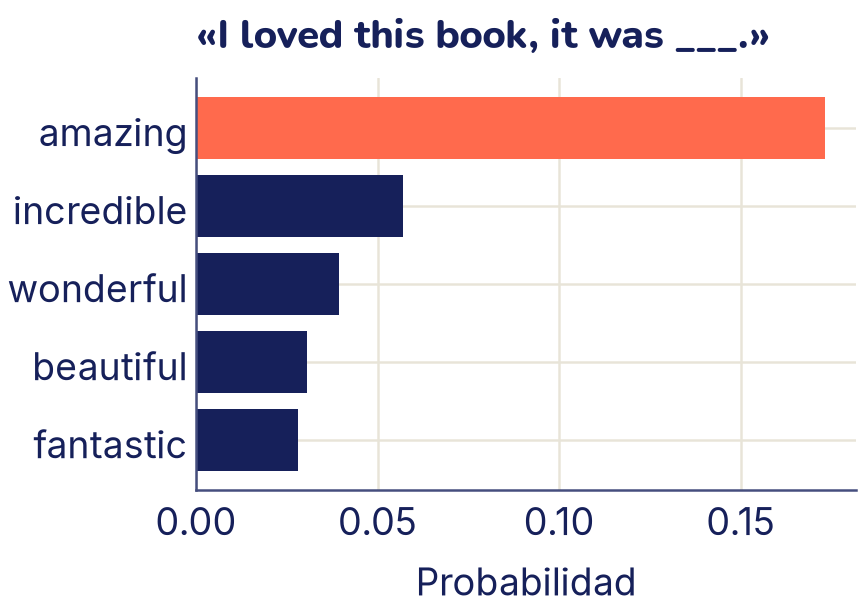

In [ ]:
palabras, probs = completar("I loved this book, it was [MASK].")
colores = ["C1"] + ["C0"] * (len(palabras) - 1)
plt.barh(palabras[::-1], probs[::-1], color=colores[::-1])
plt.xlabel("Probabilidad")
plt.title("«I loved this book, it was ___.»")
plt.show()

### El token `[CLS]` y la cabeza de clasificación

Un codificador entrega un vector por token: para «I loved this book.» son 7 vectores de 768 números cada uno. A diferencia del tema 22, donde cada palabra tenía un solo vector fijo, aquí el vector de cada token **depende de la frase**, porque pasó por las capas de atención: es un **embedding en contexto**. «Banco» recibe un vector en «me senté en el banco de la plaza» y otro distinto en «saqué plata del banco». Para clasificar el texto entero hace falta **un solo** vector. BERT usa el del primer token, `[CLS]` (de *classification*): como en cada capa ese token mira a todos los demás con atención, termina resumiendo la frase.

Sobre ese vector se pone una **cabeza**: una red pequeña, como las del tema 16, que convierte los 768 números en los logits de las clases. Al cargar el modelo con `AutoModelForSequenceClassification`, `transformers` reemplaza la cabeza de MLM por una cabeza de clasificación **nueva**, con pesos al azar. Por eso avisa (en la salida de errores) que hay pesos que «faltan» (`MISSING`): es lo esperado.

## Los datos: reseñas de Amazon

Vamos a usar `amazon_polarity`, un conjunto de reseñas de productos de Amazon en inglés marcadas como positivas (1) o negativas (0), preparado por Zhang, Zhao y LeCun (2015) a partir de un corpus de McAuley y Leskovec (2013). La ficha en Hugging Face declara licencia Apache-2.0. Son reseñas reales escritas por personas, así que alguna puede tener lenguaje ofensivo.

¿Por qué en inglés? Porque los modelos chicos y abiertos, y los datasets grandes con una licencia libre, están sobre todo en inglés: no encontramos reseñas en español con una licencia clara. Vamos a traducir las frases de ejemplo, y en el mini-proyecto verás qué pasa cuando el modelo recibe reseñas en español.

Bajamos solo el archivo de prueba (400 000 reseñas, 117 MB) y tomamos una muestra al azar: 1500 para entrenar y 400 para validar.

¿Por qué tan pocas? Para que todo el tema corra en unos minutos en una computadora sin GPU. Con más reseñas, el ajuste mejoraría (lo compruebas en el ejercicio 4).

In [ ]:
import textwrap
from huggingface_hub import hf_hub_download
from datasets import load_dataset

ruta = hf_hub_download("fancyzhx/amazon_polarity",
                       "amazon_polarity/test-00000-of-00001.parquet",
                       repo_type="dataset")
resenas = load_dataset("parquet", data_files=ruta, split="train")
muestra = resenas.shuffle(seed=0).select(range(1900))

# Título y texto de cada reseña juntos; la etiqueta 1 es positiva
datos = [(f"{r['title']}. {r['content']}", r["label"]) for r in muestra]
entrenamiento, validacion = datos[:1500], datos[1500:]

print(len(resenas), "reseñas en el archivo")
for nombre, parte in [("Entrenamiento", entrenamiento),
                      ("Validación", validacion)]:
    positivas = sum(etiqueta for _, etiqueta in parte)
    print(f"{nombre}: {len(parte)} reseñas, {positivas} positivas")
texto, etiqueta = entrenamiento[0]
print(textwrap.fill(texto[:230] + "…", 76), "→", etiqueta)

400000 reseñas en el archivo
Entrenamiento: 1500 reseñas, 759 positivas
Validación: 400 reseñas, 193 positivas
Very Awesome!. My son is very happy to have this game! It was used but the
disc had no singe scratch on it! Very awesome game!… → 1


Las clases están casi equilibradas: un modelo que siempre dijera «negativa» acertaría 207 de 400, casi un 52 %. Ese es el piso a superar.

## El bucle, versión texto

El bucle es el del tema 18, con dos cambios. Primero, cada lote es un **diccionario** con los IDs de los tokens (`input_ids`), la máscara de padding (`attention_mask`, tema «Texto como datos») y las etiquetas (`labels`). Segundo, los modelos de `transformers` calculan la pérdida ellos mismos cuando reciben `labels`: es la misma entropía cruzada de siempre, en `salida.loss`.

Cada lote se rellena solo hasta su reseña más larga (y se corta en 128 tokens), para no gastar cálculos en padding. Guardamos la pérdida de **cada lote** para poder dibujar la curva, porque vamos a entrenar una sola época.

In [ ]:
from torch.utils.data import DataLoader


def juntar(lote):
    """Tokeniza una lista de (texto, etiqueta) y la rellena al más largo."""
    textos = [texto for texto, _ in lote]
    x = tokenizador(textos, truncation=True, max_length=128,
                    padding=True, return_tensors="pt")
    x["labels"] = torch.tensor([etiqueta for _, etiqueta in lote])
    return x


def cargador_entrenamiento():
    # El mismo orden de lotes cada vez, para comparar en igualdad
    return DataLoader(entrenamiento, batch_size=16, shuffle=True,
                      collate_fn=juntar,
                      generator=torch.Generator().manual_seed(0))


cargador_val = DataLoader(validacion, batch_size=32, collate_fn=juntar)


def ajustar(modelo, tasa):
    """Una época del bucle; devuelve la pérdida de cada lote."""
    modelo.to(device)
    # Solo se optimizan los parámetros que no están congelados
    entrenables = [p for p in modelo.parameters() if p.requires_grad]
    optimizador = torch.optim.AdamW(entrenables, lr=tasa)
    modelo.train()
    perdidas = []
    for lote in cargador_entrenamiento():
        lote = lote.to(device)
        optimizador.zero_grad()
        salida = modelo(**lote)          # con labels, trae la pérdida
        salida.loss.backward()
        optimizador.step()
        perdidas.append(salida.loss.item())
    return perdidas


def medir(modelo):
    """Pérdida media y exactitud en el conjunto de validación."""
    modelo.eval()
    suma, aciertos = 0.0, 0
    with torch.no_grad():
        for lote in cargador_val:
            lote = lote.to(device)
            salida = modelo(**lote)
            etiquetas = lote["labels"]
            suma += salida.loss.item() * len(etiquetas)
            aciertos += (salida.logits.argmax(dim=1) == etiquetas).sum()
    return suma / len(validacion), aciertos.item() / len(validacion)

Dos funciones más: una que cuenta parámetros (los entrenables y el total) y otra que entrena, mide y guarda los resultados de cada manera de ajustar, para compararlas al final.

In [ ]:
from transformers import AutoModelForSequenceClassification


def nuevo_clasificador():
    """DistilBERT preentrenado con una cabeza nueva de 2 clases."""
    torch.manual_seed(0)            # la misma cabeza inicial cada vez
    return AutoModelForSequenceClassification.from_pretrained(
        NOMBRE, num_labels=2)


def contar(modelo):
    entrenables = sum(p.numel() for p in modelo.parameters()
                      if p.requires_grad)
    total = sum(p.numel() for p in modelo.parameters())
    return entrenables, total


resultados = {}


def probar(nombre, modelo, tasa):
    perdidas = ajustar(modelo, tasa)
    perdida_val, exactitud = medir(modelo)
    entrenables, total = contar(modelo)
    resultados[nombre] = {"entrenables": entrenables,
                          "perdidas": perdidas, "exactitud": exactitud}
    print(f"{nombre}: {entrenables:,} de {total:,} entrenables"
          .replace(",", " "))
    print(f"  validación: pérdida {perdida_val:.3f}, "
          f"exactitud {exactitud:.3f}")

## Primera forma: entrenar solo la cabeza

La forma más barata de reutilizar un modelo es **congelarlo**: sus pesos no cambian (`requires_grad = False`) y solo se entrena la cabeza nueva. El codificador funciona como un **extractor de variables**: convierte cada reseña en un vector de 768 números, y la cabeza aprende a separarlas, como la regresión logística del tema 8 sobre variables que tú no tuviste que diseñar.

Como la cabeza empieza de cero y es pequeña, admite una tasa de aprendizaje relativamente alta (0,001).

In [ ]:
cabeza = nuevo_clasificador()
for p in cabeza.distilbert.parameters():    # el codificador, congelado
    p.requires_grad = False
probar("Solo la cabeza", cabeza, tasa=1e-3)

Solo la cabeza: 592 130 de 66 955 010 entrenables
  validación: pérdida 0.378, exactitud 0.855


Con solo una época y 1500 reseñas, 85,5 % de acierto: el codificador ya sabía distinguir mucho de lo que importa. La cabeza de DistilBERT son dos capas lineales (768 → 768 → 2); por eso tiene 592 130 parámetros: 768 · 768 + 768 en la primera y 768 · 2 + 2 en la segunda. Es menos del 1 % del modelo.

## Segunda forma: ajustar todo el modelo

En el **ajuste fino completo** se descongela todo: los 67 millones de parámetros cambian un poco para acomodarse a tu tarea. Lo importante es **cuánto**: con una tasa de aprendizaje grande, los primeros lotes (con la cabeza todavía al azar) empujarían los pesos lejos de lo que el modelo sabía, y se perdería lo aprendido en el preentrenamiento. A eso se le llama **olvido catastrófico**. Por eso el ajuste completo usa una tasa unas 20 veces menor: 0,00005.

In [ ]:
completo = nuevo_clasificador()
probar("Completo", completo, tasa=5e-5)

Completo: 66 955 010 de 66 955 010 entrenables
  validación: pérdida 0.304, exactitud 0.885


Mejor: 88,5 %. Al poder cambiar todas sus capas, el modelo afina cómo lee las reseñas, no solo cómo decide al final. Pero hay un costo. Hay que calcular y guardar un gradiente por cada uno de los 67 millones de parámetros, el optimizador AdamW guarda dos números más por parámetro, y al final tienes una copia nueva de **todo** el modelo (268 MB) por cada tarea que ajustes. Con modelos de miles de millones de parámetros, eso ya no entra en una computadora común.

## Tercera forma: LoRA

**LoRA** (*Low-Rank Adaptation*, «adaptación de rango bajo», Hu y otros, 2021) busca lo mejor de los dos mundos: tocar todas las capas que importan, pero entrenando pocos números.

La idea es la de la actividad. Ajustar una matriz de pesos *W* es sumarle un cambio *ΔW*. LoRA congela *W* y escribe el cambio como el producto de dos matrices delgadas:

$${W}^{'} = W + \frac{\alpha}{r} \cdot B \cdot A$$

- *W* es la matriz original (en DistilBERT, de 768 × 768), **congelada**.
- *B* es de 768 × *r* y *A* de *r* × 768. Son lo único que se entrena. Con *r* = 8, son 2 · 768 · 8 = 12 288 números en lugar de 589 824: un 2 %.
- *B* empieza en ceros, así que al principio *B*·*A* = 0 y el modelo es exactamente el preentrenado. El ajuste parte de lo que el modelo ya sabe.
- *α* (alfa) es una constante que regula cuánto pesa el cambio; con *α* = 16 y *r* = 8, el cambio se multiplica por 2.

La apuesta de LoRA es que el cambio que necesita una tarea nueva tiene **rango bajo**: se describe con pocos patrones, como la pagoda con pocos rangos. El artículo original mostró que suele ser así.

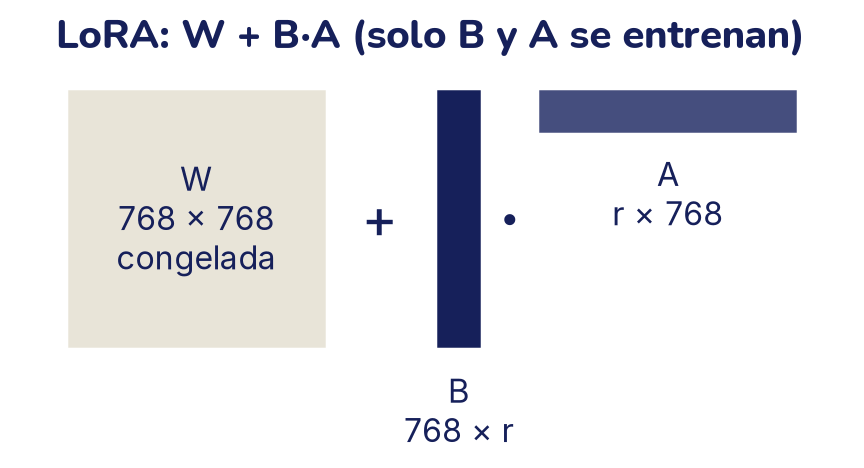

In [ ]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(4.8, 2.6))
# Dibujo esquemático: r está exagerado para que se vea
r_dibujo = 0.16
piezas = [(0.0, 0.0, 1.0, 1.0, "C3", "W\n768 × 768\ncongelada"),
          (1.45, 0.0, r_dibujo, 1.0, "C0", "B"),
          (1.85, 1.0 - r_dibujo, 1.0, r_dibujo, "C2", "A")]
for x, y, ancho, alto, color, texto in piezas:
    ax.add_patch(Rectangle((x, y), ancho, alto, color=color))
ax.text(0.5, 0.5, piezas[0][5], ha="center", va="center", fontsize=13)
ax.text(1.45 + r_dibujo / 2, -0.1, "B\n768 × r", ha="center", va="top",
        fontsize=13)
ax.text(2.35, 0.75, "A\nr × 768", ha="center", va="top", fontsize=13)
ax.text(1.22, 0.5, "+", ha="center", va="center", fontsize=22)
ax.text(1.73, 0.5, "·", ha="center", va="center", fontsize=34)
ax.set_xlim(-0.05, 2.9)
ax.set_ylim(-0.45, 1.05)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("LoRA: W + B·A (solo B y A se entrenan)")
plt.show()

¿Dónde se ponen las matrices B y A? En la atención del tema «Atención y transformers», cada capa tiene matrices que calculan las consultas (Q), las claves (K) y los valores (V). El artículo de LoRA encontró que adaptar Q y V ya funciona bien. En DistilBERT esas capas se llaman `q_lin` y `v_lin`, y hay una de cada una en cada una de las 6 capas. La librería `peft` de Hugging Face (Apache-2.0) agrega B y A a esas capas y congela todo lo demás.

In [ ]:
from peft import LoraConfig, get_peft_model

config = LoraConfig(task_type="SEQ_CLS", r=8, lora_alpha=16,
                    lora_dropout=0.1, target_modules=["q_lin", "v_lin"])
lora = get_peft_model(nuevo_clasificador(), config)

# Cuántos números agrega LoRA: 6 capas, 2 matrices, B y A
solo_lora = sum(p.numel() for n, p in lora.named_parameters()
                if "lora_" in n)
print("Parámetros de LoRA:", solo_lora, "=", 6 * 2 * (768 * 8 + 8 * 768))
probar("LoRA (r = 8)", lora, tasa=5e-4)

Parámetros de LoRA: 147456 = 147456
LoRA (r = 8): 739 586 de 67 694 596 entrenables
  validación: pérdida 0.280, exactitud 0.890


Con `task_type="SEQ_CLS"`, `peft` también entrena la cabeza de clasificación (que es nueva y no puede quedar al azar): por eso los entrenables son 147 456 de LoRA más 592 130 de la cabeza. El total sube un poco porque B y A son parámetros nuevos que se agregan al modelo. LoRA usa una tasa intermedia (0,0005): B y A empiezan en cero y tienen que crecer, pero el resto del modelo no se mueve.

Resultado: 89 %, lo mismo que el ajuste completo (la diferencia, 2 reseñas de 400, es ruido), entrenando el 1,1 % de los parámetros. Y lo que hay que guardar para esta tarea son solo B, A y la cabeza: unos 3 MB en lugar de 268 MB.

## Comparar las tres formas

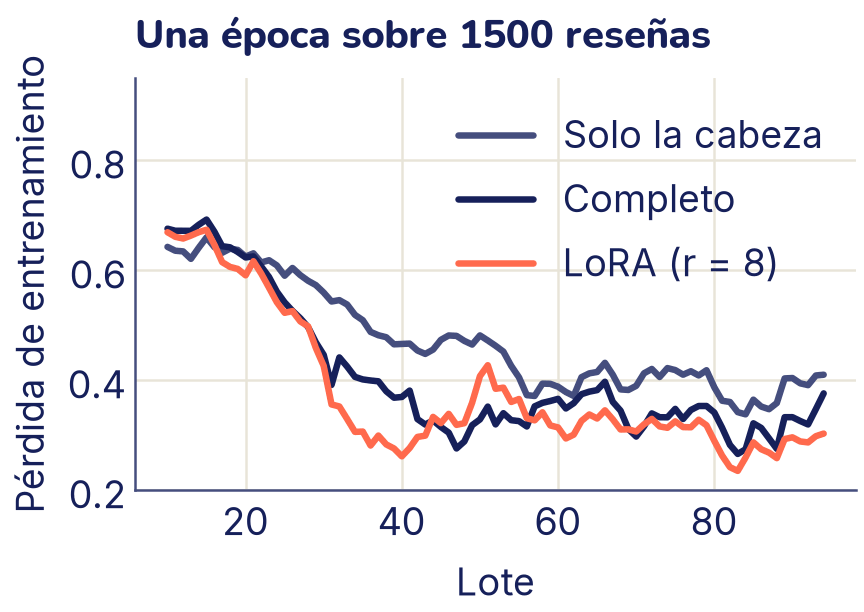

In [ ]:
nombres = list(resultados)
plt.figure()
for nombre, color in zip(nombres, ["C2", "C0", "C1"]):
    perdidas = np.array(resultados[nombre]["perdidas"])
    # Promedio móvil de 10 lotes, para ver la tendencia
    suave = np.convolve(perdidas, np.ones(10) / 10, mode="valid")
    plt.plot(np.arange(10, len(perdidas) + 1), suave, color=color,
             label=nombre)
plt.xlabel("Lote")
plt.ylabel("Pérdida de entrenamiento")
plt.title("Una época sobre 1500 reseñas")
# Espacio arriba para la leyenda
plt.ylim(0.2, 0.95)
plt.legend(loc="upper right")
plt.show()

Las tres curvas empiezan cerca de 0,69, la pérdida de un modelo que dice «50 % y 50 %» a todo (ln 2, tema 8). La de solo la cabeza baja más despacio y se queda más arriba; la del ajuste completo y la de LoRA bajan juntas. Las curvas saltan porque cada lote tiene solo 16 reseñas, unas más fáciles que otras. La pérdida en validación cuenta lo mismo que la de entrenamiento: 0,378 con la cabeza sola, 0,304 con el ajuste completo y 0,280 con LoRA, así que no hay sobreajuste en una sola época.

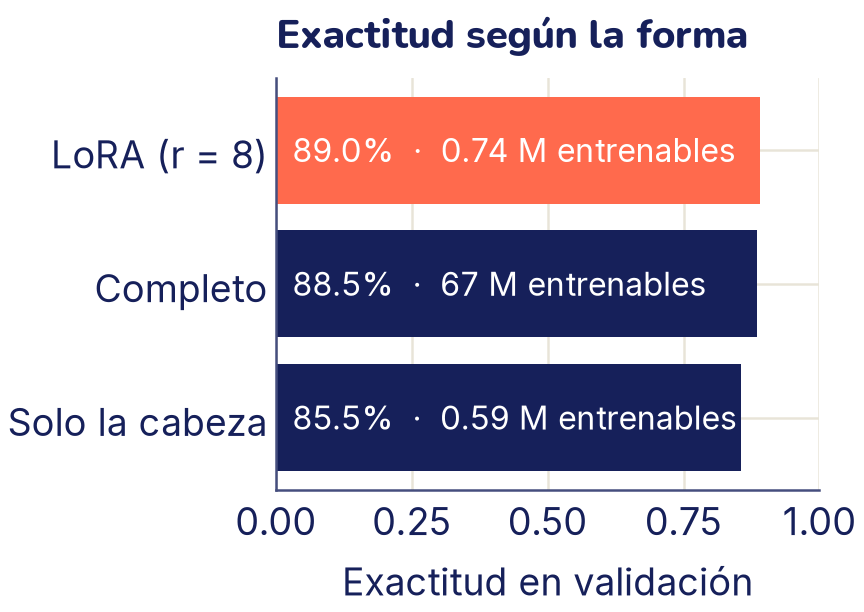

In [ ]:
exactitudes = [resultados[n]["exactitud"] for n in nombres]
entrenables = [resultados[n]["entrenables"] for n in nombres]
plt.figure()
plt.barh(nombres, exactitudes, color=["C0", "C0", "C1"])
for i, (e, n) in enumerate(zip(exactitudes, entrenables)):
    texto = f"{n / 1e6:.2f} M" if n < 1e7 else f"{n / 1e6:.0f} M"
    plt.text(0.03, i, f"{e:.1%}  ·  {texto} entrenables", va="center",
             color="white", fontsize=13)
plt.xlim(0, 1)
plt.xlabel("Exactitud en validación")
plt.title("Exactitud según la forma")
plt.show()

| Forma | Parámetros entrenables | Exactitud | Tiempo de una época (completo = 1)* |
|---|---|---|---|
| Solo la cabeza | 592 130 (0,9 %) | 85,5 % | unos 0,45 |
| Completo | 66 955 010 (100 %) | 88,5 % | 1 |
| LoRA, *r* = 8 | 739 586 (1,1 %) | 89,0 % | unos 0,8 |

\* Proporción entre los tiempos medidos al preparar este tema, en una computadora sin GPU con 2 hilos de CPU (en esa medición se usaron 2000 reseñas rellenadas todas a 128 tokens; con la configuración del tema todo tarda menos). En tu computadora o en Colab los segundos serán otros, pero la proporción se parece.

Mira la última columna con cuidado: **LoRA no es mucho más rápido que el ajuste completo**. Aunque entrena pocos parámetros, cada lote tiene que pasar por todo el modelo hacia adelante y el gradiente tiene que volver por todas las capas hasta llegar a las B y A de la primera. Lo que LoRA ahorra es **memoria** (gradientes y estado del optimizador solo para 0,74 M de números) y **espacio**: un mismo modelo base sirve para muchas tareas, cada una con sus 3 MB de B y A. Por eso se usa para ajustar modelos de miles de millones de parámetros en una sola GPU.

¿Y cuál usar?

- **Solo la cabeza**: cuando tienes muy pocos datos, poco cómputo o quieres probar rápido. También es la opción si vas a calcular los embeddings una vez y reutilizarlos.
- **LoRA**: la opción por defecto para ajustar modelos grandes; casi siempre cerca del ajuste completo.
- **Completo**: cuando tienes bastantes datos, el modelo es chico y quieres exprimir el último punto.

Una última prueba: el modelo con LoRA frente a reseñas que escribimos nosotros (no son de Amazon).

In [ ]:
def probabilidad_positiva(modelo, textos):
    modelo.eval()
    x = tokenizador(textos, truncation=True, max_length=128,
                    padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = modelo(**x).logits.softmax(dim=-1)[:, 1]
    return probs.tolist()


propias = ["Not bad at all, it works better than I expected.",
           "I returned it the next day.",
           "Great price, but it broke after a week."]
for texto, p in zip(propias, probabilidad_positiva(lora, propias)):
    print(f"{p:.2f}  {texto}")

0.45  Not bad at all, it works better than I expected.
0.38  I returned it the next day.
0.38  Great price, but it broke after a week.


Las tres quedan por debajo de 0,5, así que el modelo las llama negativas. Acierta las dos últimas, aunque con poca seguridad, y se equivoca con «Not bad at all», una negación que engaña. Son frases mucho más cortas que las reseñas con que se entrenó (título y texto, de unas 90 palabras), y una época con 1500 reseñas no alcanza para todo. Probar el modelo con casos propios, y no solo mirar la exactitud, es como se encuentran estos huecos. En el mini-proyecto vas a ver en qué reseñas sí le gana a TF-IDF.

## Traducir con atención cruzada

Ahora la tercera familia. Un modelo **codificador-decodificador** tiene dos transformers:

1. El **codificador** lee la entrada completa (una frase en inglés) y produce un vector por token, como BERT.
2. El **decodificador** genera la salida (la frase en español) un token a la vez, como el modelo de lenguaje del tema «Modelos de lenguaje», con máscara causal.
3. En cada capa del decodificador hay, además, una **atención cruzada**: las consultas (Q) salen del decodificador y las claves y valores (K y V) salen de los vectores del codificador. Así, para escribir cada palabra, el decodificador «mira» las partes de la entrada que le sirven.

Vamos a usar **Marian** `opus-mt-en-es`, de Helsinki-NLP (proyecto OPUS-MT, Tiedemann y Thottingal, 2020; licencia Apache-2.0; 312 MB). En `transformers` 5 se carga con `AutoModelForSeq2SeqLM` y se usa con `generate`. Usamos generación **codiciosa** (`do_sample=False`), como en el tema «Modelos de lenguaje»: siempre se elige el token más probable, así que el resultado sale igual cada vez.

In [ ]:
from transformers import AutoModelForSeq2SeqLM

tok_en_es = AutoTokenizer.from_pretrained("Helsinki-NLP/opus-mt-en-es")
# "eager": la atención clásica, que puede devolver sus pesos
en_es = AutoModelForSeq2SeqLM.from_pretrained(
    "Helsinki-NLP/opus-mt-en-es", attn_implementation="eager"
).to(device).eval()


def traducir(frases, tok, modelo):
    x = tok(frases, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        ids = modelo.generate(**x, do_sample=False, num_beams=1,
                              max_new_tokens=60)
    return tok.batch_decode(ids, skip_special_tokens=True)


frases = ["The black cat sleeps on the old chair.",
          "Not bad at all, it works better than I expected.",
          "I returned it the next day."]
for original, traduccion in zip(frases, traducir(frases, tok_en_es,
                                                 en_es)):
    print(original)
    print("  →", traduccion)

The black cat sleeps on the old chair.
  → El gato negro duerme en la silla vieja.
Not bad at all, it works better than I expected.
  → No está mal, funciona mejor de lo que esperaba.
I returned it the next day.
  → Lo devolví al día siguiente.


Fíjate en «black cat» → «gato negro» y «old chair» → «silla vieja»: el orden cambia entre los idiomas. Un traductor palabra por palabra no podría hacerlo; la atención cruzada sí, porque en cada paso puede mirar a cualquier parte de la entrada. Podemos ver adónde mira: pasamos la traducción por el modelo (el decodificador recibe los tokens ya generados) y pedimos los pesos de atención.

Entrada: The black cat sleep s on the old chair . </s>
Salida:  El gato negro duerme en la silla vieja . </s>


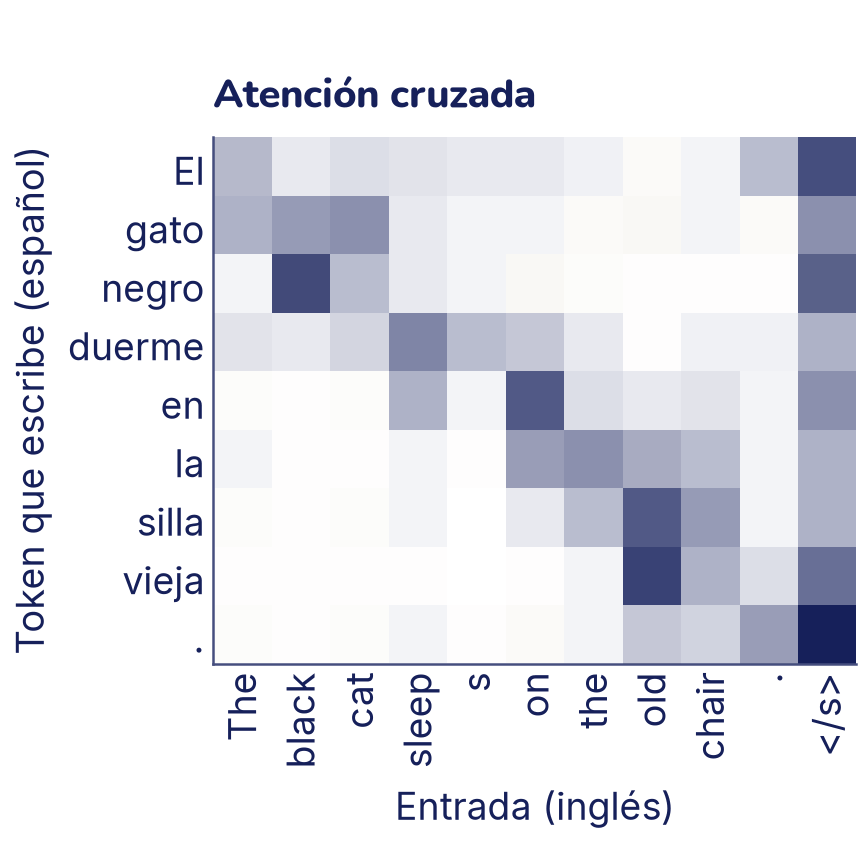

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

x = tok_en_es(frases[0], return_tensors="pt").to(device)
with torch.no_grad():
    ids = en_es.generate(**x, do_sample=False, num_beams=1)
    salida = en_es(**x, decoder_input_ids=ids[:, :-1],
                   output_attentions=True)
# Cuarta capa de 6, promedio de sus 8 cabezas: (salida, entrada)
pesos = salida.cross_attentions[3][0].mean(dim=0).cpu().numpy()
# En Marian, «▁» marca el comienzo de una palabra, como «Ġ» en Qwen
entrada = [t.replace("▁", "") for t in
           tok_en_es.convert_ids_to_tokens(x["input_ids"][0])]
generada = [t.replace("▁", "") for t in
            tok_en_es.convert_ids_to_tokens(ids[0, 1:])]
print("Entrada:", " ".join(entrada))
print("Salida: ", " ".join(generada))

tinta = LinearSegmentedColormap.from_list("tinta", ["white", "C0"])
plt.figure(figsize=(4.8, 4.8))
plt.imshow(pesos[:-1], cmap=tinta)     # sin la fila de </s>
plt.xticks(range(len(entrada)), entrada, rotation=90)
plt.yticks(range(len(generada) - 1), generada[:-1])
plt.xlabel("Entrada (inglés)")
plt.ylabel("Token que escribe (español)")
plt.title("Atención cruzada")
plt.grid(False)
plt.show()

Cada fila es un token que el decodificador está escribiendo, y cada celda oscura, la parte de la entrada que más miró para escribirlo. Al escribir «gato» mira a *cat*, y al escribir «negro», a *black*: las dos celdas se cruzan, porque el orden se invierte. Elegimos la cuarta capa porque ahí la alineación es más clara; en otras capas y cabezas la atención se reparte de otras formas (mucha va al token de fin `</s>`), así que un mapa de atención es una pista de lo que hace el modelo, no una explicación completa.

## Describir imágenes

El codificador no tiene que leer texto. En un modelo **visión-lenguaje** el codificador es un transformer de visión que parte la imagen en parches, como el ViT del tema «Atención y transformers», y el decodificador escribe una frase sobre la imagen mirando esos parches con atención cruzada. Es el mismo esquema que la traducción: de «imagen» a «inglés».

Vamos a usar **Florence-2** (`Florence-2-base-ft`, de Microsoft, en la versión para `transformers` de `florence-community`; licencia MIT; 230 M de parámetros, 463 MB). Florence-2 hace varias tareas según el texto que recibe junto con la imagen; `<CAPTION>` le pide una descripción corta. Lo cargamos con `AutoModelForImageTextToText` y su `AutoProcessor`, que prepara la imagen y el texto. Las fotos son las dos de ejemplo de scikit-learn. Para generar usamos búsqueda en haz (`num_beams=3`): en cada paso se siguen las 3 frases parciales más probables y al final se elige la mejor. Tampoco usa azar, así que el resultado es siempre el mismo.

china.jpg: A pagoda building overlooks a body of water.
flower.jpg: A close up of a flower with a blurry background.
→ Un edificio pagoda tiene vistas a un cuerpo de agua.
→ Un primer plano de una flor con un fondo borroso.


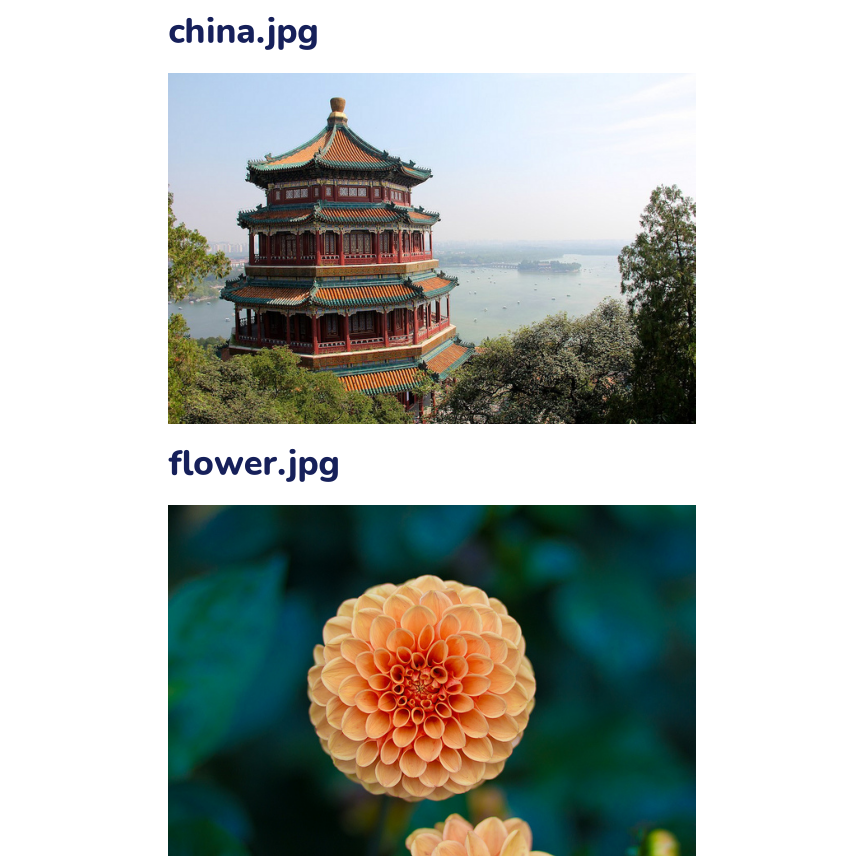

In [ ]:
from PIL import Image
from sklearn.datasets import load_sample_image
from transformers import AutoProcessor, AutoModelForImageTextToText

FLORENCE = "florence-community/Florence-2-base-ft"
procesador = AutoProcessor.from_pretrained(FLORENCE)
descriptor = AutoModelForImageTextToText.from_pretrained(FLORENCE)
descriptor = descriptor.to(device).eval()

fotos = {n: load_sample_image(n) for n in ["china.jpg", "flower.jpg"]}
descripciones = []
for nombre, foto in fotos.items():
    x = procesador(text="<CAPTION>", images=Image.fromarray(foto),
                   return_tensors="pt").to(device)
    with torch.no_grad():
        ids = descriptor.generate(**x, do_sample=False, num_beams=3,
                                  max_new_tokens=30)
    texto = procesador.batch_decode(ids, skip_special_tokens=True)[0]
    descripciones.append(texto)
    print(f"{nombre}: {texto}")

# Y en español, con el traductor de la sección anterior
for texto in traducir(descripciones, tok_en_es, en_es):
    print("→", texto)

fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.8))
for eje, (nombre, foto) in zip(ejes, fotos.items()):
    eje.imshow(foto)
    eje.set_title(nombre, fontsize=14)
    eje.axis("off")
plt.show()

Las dos descripciones son correctas y generales. Encadenamos dos modelos codificador-decodificador (imagen → inglés → español), y la traducción es literal («un cuerpo de agua» viene de *a body of water*): los errores de cada paso se suman. Las fotos de scikit-learn son de Flickr, con licencia CC BY 2.0.

## Cuando los datos cambian: cambio de dominio y olvido

Todo lo que mediste hasta aquí fue en validación: datos que el modelo no vio, pero sacados del mismo lugar que los de entrenamiento. En la vida real los datos cambian. Una tienda cambia de cámara y sus fotos salen más oscuras; llegan productos que antes no vendía. Eso trae dos problemas:

- **Cambio de dominio** (*domain shift*): la tarea es la misma, pero las entradas se ven distintas de las del entrenamiento. El **dominio** es el lugar de donde vienen los datos (qué cámara, qué época, qué público).
- **Olvido catastrófico**: al entrenar con datos nuevos, el modelo pierde lo que sabía hacer con los viejos. Ya apareció en el ajuste completo de DistilBERT; aquí lo vas a ver ocurrir.

Reproducirlos con DistilBERT costaría varios minutos por prueba. Para verlos en segundos usamos el clasificador de prendas del tema 18: un MLP pequeño sobre FashionMNIST (de Zalando Research, licencia MIT). Primero, la función `entrenar` del tema 18, tal cual (con su compañera `evaluar`). Cópiala en tu cuaderno; no la volvemos a explicar.

In [ ]:
import torch
from torch import nn


def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

Para que todo corra rápido usamos 24 000 fotos al azar: 20 000 para entrenar y 4000 para validar. A diferencia del tema 18, no estandarizamos: dividimos entre 255 para que cada píxel quede entre 0 (negro) y 1 (blanco), y así «oscurecer» una foto es solo multiplicarla por un número menor que 1. La red es la misma del tema 18 (784 → 128 → 10), escrita con `nn.Sequential`, y la entrenamos 3 épocas.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

moda = datasets.FashionMNIST(root="datos", train=True, download=True)
NOMBRES = ["Polera", "Pantalón", "Chompa", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]
orden = torch.randperm(len(moda.data),
                       generator=torch.Generator().manual_seed(0))
X_moda = moda.data[orden[:24000]].float().div(255).unsqueeze(1)
y_moda = moda.targets[orden[:24000]]
X_ent, y_ent = X_moda[:20000], y_moda[:20000]
X_val, y_val = X_moda[20000:], y_moda[20000:]


def lotes(X, y, mezclar=False):
    """Un DataLoader de lotes de 128 (mezclados) o de 1000 (en orden)."""
    if mezclar:
        return DataLoader(TensorDataset(X, y), batch_size=128,
                          shuffle=True,
                          generator=torch.Generator().manual_seed(0))
    return DataLoader(TensorDataset(X, y), batch_size=1000)


def red_nueva():
    torch.manual_seed(0)      # los mismos pesos iniciales cada vez
    return nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(),
                         nn.Linear(128, 10))


red = red_nueva()
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)
historial = entrenar(red, lotes(X_ent, y_ent, mezclar=True),
                     lotes(X_val, y_val), 3, optimizador)

Época 1: pérdida 0.804, validación 0.543, exactitud de validación 0.816
Época 2: pérdida 0.524, validación 0.452, exactitud de validación 0.848
Época 3: pérdida 0.468, validación 0.430, exactitud de validación 0.849


### Mismas prendas, otras fotos

Ahora fingimos que llegan fotos de otro dominio. Probamos tres cambios sobre las mismas 4000 fotos de validación: girarlas un cuarto de vuelta, oscurecerlas (cada píxel por 0,4) y agregarles ruido (a cada píxel se le suma un número al azar de una normal con desviación 0,3). Las prendas y las etiquetas son las mismas; solo cambia cómo se ven.

Normal     exactitud 0.849
Rotada     exactitud 0.017
Oscura     exactitud 0.804
Con ruido  exactitud 0.639


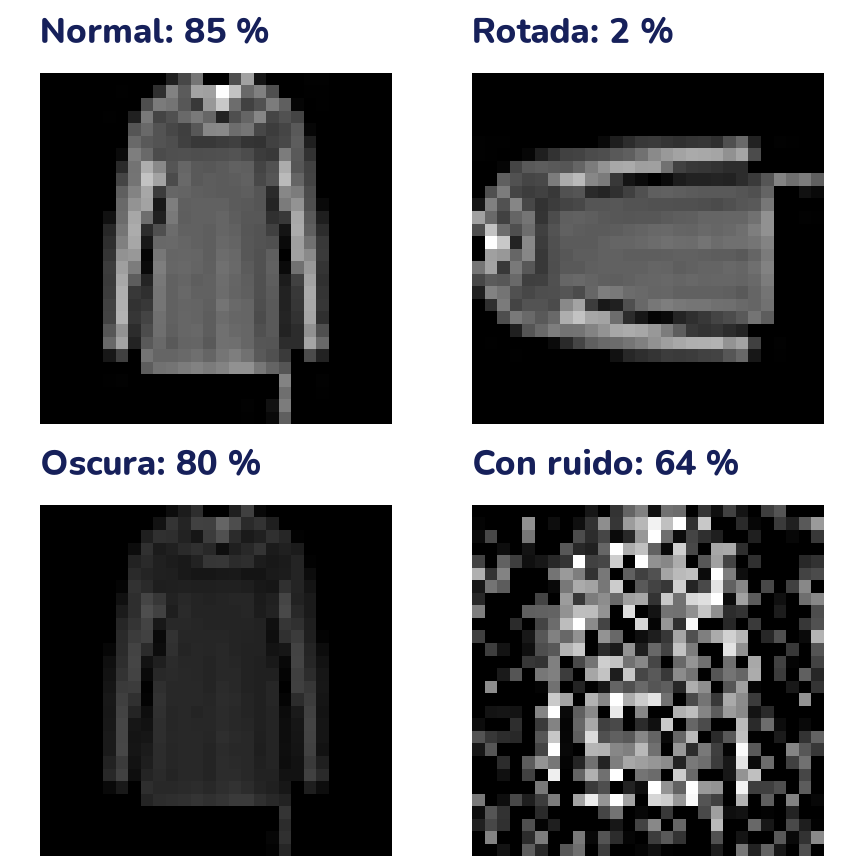

In [ ]:
azar = torch.Generator().manual_seed(1)
ruido = torch.randn(X_val.shape, generator=azar)
dominios = {
    "Normal": X_val,
    # rot90 gira un cuarto de vuelta en los ejes 2 y 3 (alto y ancho)
    "Rotada": torch.rot90(X_val, 1, dims=(2, 3)),
    "Oscura": 0.4 * X_val,
    # clamp recorta: lo que pasa de 1 queda en 1 y lo negativo, en 0
    "Con ruido": (X_val + 0.3 * ruido).clamp(0, 1),
}
funcion_perdida = nn.CrossEntropyLoss()
acierto_dominio = {}
for nombre, X_d in dominios.items():
    _, acierto_dominio[nombre] = evaluar(red, lotes(X_d, y_val),
                                         funcion_perdida)
    print(f"{nombre:10} exactitud {acierto_dominio[nombre]:.3f}")

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, (nombre, X_d) in zip(ejes.flat, dominios.items()):
    eje.imshow(X_d[0, 0], cmap="gray", vmin=0, vmax=1)
    eje.set_title(f"{nombre}: {acierto_dominio[nombre] * 100:.0f} %",
                  fontsize=14)
    eje.axis("off")
plt.show()

Con `cmap="gray"` cada píxel se dibuja como en la foto: 0 es negro y 1 es blanco.

La red no aprendió «qué es un pantalón»: aprendió cómo se ven los pantalones **en estas fotos**, siempre derechos, con la misma luz y sin ruido. Lo oscuro le afecta poco y el ruido bastante. Girar las fotos la hunde hasta un 1,7 %, mucho peor que adivinar al azar (10 %): no está adivinando, se equivoca de forma sistemática (por ejemplo, un pantalón acostado se parece más a un bolso que a un pantalón).

### ¿Cómo darte cuenta?

Cuando el modelo ya está en uso, las fotos nuevas no traen etiqueta: no puedes medir la exactitud. Hay que mirar otras señales. Probamos dos:

- **La confianza**: la probabilidad más alta que da el softmax a cada foto. Si el modelo está «perdido», debería dudar más.
- **Las entradas mismas**: comparamos la foto promedio del lote nuevo con la foto promedio del entrenamiento, píxel por píxel. Si los datos son del mismo dominio, deberían parecerse.

In [ ]:
promedio_ent = X_ent.mean(dim=0)          # la foto promedio, (1, 28, 28)
for nombre, X_d in dominios.items():
    with torch.no_grad():
        # max devuelve los valores y sus posiciones; .values, los valores
        confianza = red(X_d).softmax(dim=1).max(dim=1).values
    distancia = (X_d.mean(dim=0) - promedio_ent).abs().mean()
    print(f"{nombre:10} confianza media {confianza.mean():.2f}, "
          f"distancia {distancia:.3f}")

Normal     confianza media 0.82, distancia 0.004
Rotada     confianza media 0.81, distancia 0.109
Oscura     confianza media 0.57, distancia 0.173
Con ruido  confianza media 0.73, distancia 0.056


La confianza baja con las fotos con ruido y mucho con las oscuras (aunque con esas la red sigue acertando el 80 %), pero **no con las rotadas**: ahí la red se equivoca en casi todo con la misma seguridad que cuando acierta (0,81 frente a 0,82). Un modelo puede estar muy seguro y muy equivocado a la vez, sobre todo con entradas distintas de las que vio. La distancia entre fotos promedio, en cambio, salta en los tres casos: de 0,004 con la validación normal a entre 0,056 y 0,173. Por eso en la práctica se vigilan varias señales a la vez: las entradas (promedios, histogramas), la confianza y, cuando se puede, la exactitud sobre unos pocos ejemplos nuevos etiquetados a mano.

¿Y el remedio? El mismo de todo el tema: **ajustar con pocos ejemplos del dominio nuevo**. Supongamos que etiquetamos 500 fotos rotadas. Ajustamos una copia de la red con ellas, y otra copia con esas 500 mezcladas con 500 normales. `copy.deepcopy` hace una copia completa e independiente de la red, con sus pesos: entrenar la copia no cambia la original.

In [ ]:
import copy

X_rot = torch.rot90(X_ent[:500], 1, dims=(2, 3))
y_rot = y_ent[:500]


def ajustar_copia(X, y, epocas=5):
    copia = copy.deepcopy(red)
    opt = torch.optim.Adam(copia.parameters(), lr=1e-3)
    entrenar(copia, lotes(X, y, mezclar=True), lotes(X_val, y_val),
             epocas, opt, mostrar=False)
    for nombre in ["Normal", "Rotada"]:
        _, exactitud = evaluar(copia, lotes(dominios[nombre], y_val),
                               funcion_perdida)
        print(f"  {nombre}: {exactitud:.3f}")


print("Solo con las 500 rotadas:")
ajustar_copia(X_rot, y_rot)
print("Con 500 rotadas y 500 normales:")
ajustar_copia(torch.cat([X_rot, X_ent[500:1000]]),
              torch.cat([y_rot, y_ent[500:1000]]))

Solo con las 500 rotadas:
  Normal: 0.663
  Rotada: 0.513
Con 500 rotadas y 500 normales:
  Normal: 0.779
  Rotada: 0.625


Con 500 ejemplos rotados y 5 épocas, la red pasa del 1,7 % al 51,3 % en el dominio nuevo. Pero mira la fila «Normal»: baja del 84,9 % al 66,3 %. Si solo ve fotos rotadas, empieza a olvidar las normales. Mezcladas con 500 normales, olvida mucho menos (77,9 %) y además aprende mejor el dominio nuevo (62,5 %). Con más ejemplos rotados o más épocas mejoraría más. Ese olvido es justo el siguiente problema.

### Aprender algo nuevo y olvidar lo viejo

Imagina que al principio solo tienes fotos de cinco clases (Polera, Pantalón, Chompa, Vestido y Abrigo: las clases 0 a 4) y meses después llegan las otras cinco (Sandalia, Camisa, Zapatilla, Bolso y Botín: las clases 5 a 9). Entrenamos con la **tarea A** (clases 0 a 4) y después seguimos entrenando la misma red solo con la **tarea B** (clases 5 a 9), como si los datos viejos ya no estuvieran. Esto se llama **aprendizaje continuo** (*continual learning*): aprender tareas una detrás de otra. Después de cada época medimos la exactitud en cada tarea por separado.

In [ ]:
en_A_ent, en_A_val = y_ent < 5, y_val < 5
# ~ invierte la máscara: las fotos de las clases 5 a 9
tarea_A = (X_ent[en_A_ent], y_ent[en_A_ent])
tarea_B = (X_ent[~en_A_ent], y_ent[~en_A_ent])
val_A = lotes(X_val[en_A_val], y_val[en_A_val])
val_B = lotes(X_val[~en_A_val], y_val[~en_A_val])


def por_tareas(modelo):
    _, exactitud_A = evaluar(modelo, val_A, funcion_perdida)
    _, exactitud_B = evaluar(modelo, val_B, funcion_perdida)
    return exactitud_A, exactitud_B


def en_secuencia(datos_B, congelar=False, epocas=3):
    """Tarea A y después datos_B, midiendo las dos tareas por época."""
    red_s = red_nueva()
    opt = torch.optim.Adam(red_s.parameters(), lr=1e-3)
    # *tarea_A pasa las fotos y las etiquetas como dos argumentos
    cargador_A = lotes(*tarea_A, mezclar=True)
    curva = []
    for _ in range(epocas):
        entrenar(red_s, cargador_A, val_A, 1, opt, mostrar=False)
        curva.append(por_tareas(red_s))
    if congelar:
        # La primera capa lineal, red_s[1], deja de cambiar
        for p in red_s[1].parameters():
            p.requires_grad = False
        opt = torch.optim.Adam(red_s[3].parameters(), lr=1e-3)
    cargador_B = lotes(*datos_B, mezclar=True)
    for _ in range(epocas):
        entrenar(red_s, cargador_B, val_B, 1, opt, mostrar=False)
        curva.append(por_tareas(red_s))
    return curva


sin_remedio = en_secuencia(tarea_B)
for epoca, (a, b) in enumerate(sin_remedio, start=1):
    print(f"Época {epoca}: tarea A {a:.3f}, tarea B {b:.3f}")

Época 1: tarea A 0.858, tarea B 0.000
Época 2: tarea A 0.875, tarea B 0.000
Época 3: tarea A 0.885, tarea B 0.000
Época 4: tarea A 0.000, tarea B 0.874
Época 5: tarea A 0.000, tarea B 0.926
Época 6: tarea A 0.000, tarea B 0.937


En las tres primeras épocas la red aprende la tarea A (y no sabe nada de la B: nunca vio esas clases). En cuanto pasa a la tarea B, la exactitud en la A cae **a cero**: no queda ni una prenda bien clasificada. No es que «se le olvide un poco»: cada lote de la tarea B le enseña que la respuesta correcta nunca es Polera, Pantalón, Chompa, Vestido ni Abrigo, y la red aprende justo eso. Nadie le recuerda que esas clases existen.

### Remedios baratos

Probamos dos remedios que no cuestan casi nada:

- **Repaso** (*replay*): guardar una parte pequeña de los datos viejos y mezclarla con los nuevos. Probamos con el 5 %, el 10 % y el 20 % de las fotos de la tarea A.
- **Congelar capas**: como en «Primera forma» con DistilBERT, la primera capa (la que «mira» los píxeles) deja de cambiar durante la tarea B, y solo se entrena la última.

In [ ]:
X_A, y_A = tarea_A
curvas_repaso = {}
for parte in [0.05, 0.10, 0.20]:
    k = int(parte * len(X_A))           # cuántas fotos viejas se guardan
    con_repaso = (torch.cat([tarea_B[0], X_A[:k]]),
                  torch.cat([tarea_B[1], y_A[:k]]))
    curvas_repaso[parte] = en_secuencia(con_repaso)
    a, b = curvas_repaso[parte][-1]
    print(f"Repaso del {parte:.0%} ({k} fotos): "
          f"tarea A {a:.3f}, tarea B {b:.3f}")

a, b = en_secuencia(tarea_B, congelar=True)[-1]
print(f"Congelar la primera capa: tarea A {a:.3f}, tarea B {b:.3f}")

Repaso del 5% (496 fotos): tarea A 0.310, tarea B 0.934
Repaso del 10% (992 fotos): tarea A 0.522, tarea B 0.919
Repaso del 20% (1984 fotos): tarea A 0.568, tarea B 0.922
Congelar la primera capa: tarea A 0.000, tarea B 0.599


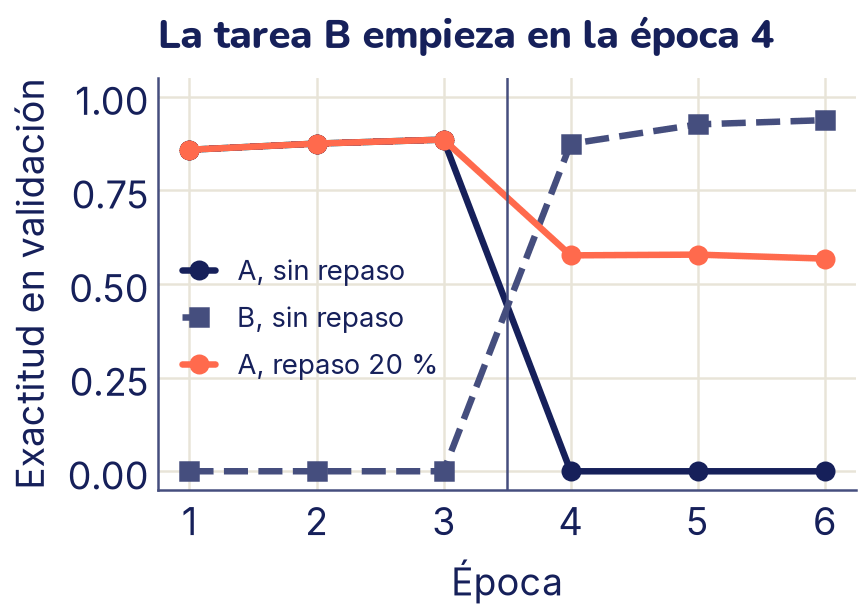

In [ ]:
epocas_x = range(1, 7)
plt.figure()
plt.plot(epocas_x, [a for a, b in sin_remedio], "o-", color="C0",
         label="A, sin repaso")
plt.plot(epocas_x, [b for a, b in sin_remedio], "s--", color="C2",
         label="B, sin repaso")
plt.plot(epocas_x, [a for a, b in curvas_repaso[0.20]], "o-",
         color="C1", label="A, repaso 20 %")
# Solo para dibujar: la línea donde termina la tarea A y empieza la B
plt.axvline(3.5, color="C2", linewidth=1)
plt.ylim(-0.05, 1.05)
plt.xlabel("Época")
plt.ylabel("Exactitud en validación")
plt.title("La tarea B empieza en la época 4")
plt.legend(loc="center left", bbox_to_anchor=(0, 0.42), fontsize=11,
           handlelength=1.2)
plt.show()

Lo que muestran los números:

- **El repaso ayuda, y cuanto más se repasa, mejor.** Con el 5 % de las fotos viejas (496), la tarea A ya no queda en cero sino en 31 %; con el 10 %, en 52,2 %, y con el 20 %, en 56,8 %, todavía lejos del 88,5 % que tenía. La tarea B casi no pierde nada (92 % o más). El costo es guardar esos datos viejos y entrenar con unos cuantos más.
- **Congelar la primera capa no alcanza aquí.** El olvido no está solo en cómo la red «mira» las fotos, sino sobre todo en la última capa, la que decide la clase: esa sigue entrenándose solo con las clases 5 a 9 y aprende a no elegir nunca las otras. Además, la tarea B aprende peor (59,9 %), porque las variables de la primera capa se formaron con ropa, no con calzado. Congelar sirve más cuando cada tarea tiene su propia cabeza, como en todo este tema: el codificador congelado de DistilBERT no olvida nada porque no cambia.

Ahí entra la idea de **LoRA**. Con LoRA los pesos originales *W* nunca cambian: lo nuevo se guarda aparte, en *B* y *A*. Si ajustas un modelo a la tarea B con LoRA, el modelo original sigue intacto: para volver a la tarea A basta con quitar *B*·*A*, y puedes tener un par de matrices pequeñas por tarea (o por cliente). Eso no hace que un solo modelo sepa las dos tareas a la vez, pero evita perder lo que ya sabía. Hay métodos más finos (por ejemplo, frenar los cambios en los pesos que más importaban para la tarea vieja), y es un área de investigación activa.

### Desaprender

A veces el problema es el contrario: hay que hacer que un modelo **olvide** algo a propósito. Por ejemplo, una persona pide que se borren sus datos, o se descubre que unas fotos estaban mal etiquetadas o no se podían usar. Esto se llama **desaprender** (*machine unlearning*). La única forma exacta es **volver a entrenar sin esos datos**, desde cero: así el modelo final es exactamente uno que nunca los vio. Con modelos grandes eso cuesta demasiado, y por eso hay métodos aproximados (ajustar el modelo para que «empeore» en esos ejemplos, o entrenar por partes separadas para reentrenar solo la parte que contenía el dato), pero ninguno garantiza del todo que no quede rastro. Si un sistema guarda datos de personas, conviene pensar desde el principio cómo se borrarán.

## Límites de reutilizar modelos

- **Costo.** Ajustar sigue costando: aquí, unos minutos por forma con 1500 reseñas cortas. Con más datos, textos largos o modelos grandes, se necesita una GPU (en Colab, la del entorno con GPU) o técnicas como LoRA.
- **Olvido catastrófico.** Un ajuste fuerte (tasa alta, muchas épocas) puede borrar lo que el modelo sabía y dejarlo bueno solo en tu tarea, o en nada. Lo viste ocurrir en «Cuando los datos cambian»; el repaso lo reduce y LoRA lo evita para el modelo original, porque sus pesos quedan intactos.
- **Sobreajuste con pocos datos.** Con 100 reseñas, un modelo de 67 millones de parámetros puede memorizarlas. Por eso se mide siempre en validación, como en el tema 7.
- **El idioma y los datos del preentrenamiento.** DistilBERT leyó inglés; con reseñas en español rinde mucho peor (lo pruebas en el mini-proyecto). Para español conviene un modelo multilingüe o uno entrenado en español. Y el modelo hereda los sesgos de los textos con que se entrenó (ejercicio 3).
- **Licencias.** «Descargable» no significa «se puede usar para cualquier cosa». Antes de usar un modelo o un dataset, lee su ficha: aquí los modelos son Apache-2.0 o MIT y las fotos, CC BY, licencias que permiten el uso educativo y comercial, siempre que se conserve el aviso de licencia y de autoría. El dataset de reseñas declara Apache-2.0, pero las reseñas originales vienen de Amazon y su origen no está del todo claro: para un uso comercial habría que revisarlo.

## Lo que aprendiste y lo que sigue

- Hay tres familias de transformers: los **codificadores** (BERT) entienden, los **decodificadores** (GPT) generan y los **codificadores-decodificadores** (Marian, Florence-2) transforman una entrada en una salida, conectados por la **atención cruzada**.
- BERT se **preentrena** adivinando tokens tapados con `[MASK]`, sin etiquetas. Para clasificar, se usa el vector del token `[CLS]` con una **cabeza** nueva.
- Hay tres formas de **ajustar**: entrenar **solo la cabeza** (barato, 85,5 % aquí), el **ajuste completo** (88,5 %, con una tasa de aprendizaje pequeña) y **LoRA** (89 % entrenando el 1,1 % de los parámetros).
- **LoRA** congela *W* y aprende un cambio de **rango bajo** *B*·*A*. Ahorra memoria y espacio, no tanto tiempo.
- Para traducir y describir imágenes en `transformers` 5 se usan las clases `Auto…` con `generate`, y con `do_sample=False` la salida es la misma cada vez.
- Si los datos nuevos se ven distintos (**cambio de dominio**), la exactitud puede caer sin aviso: la confianza del modelo no siempre lo delata, así que conviene vigilar también las entradas. Se corrige ajustando con pocos ejemplos del dominio nuevo.
- Al entrenar con una tarea nueva, una red puede **olvidar** la vieja por completo. El **repaso** de una parte de los datos viejos lo reduce; LoRA conserva el modelo original intacto. **Desaprender** un dato con exactitud exige reentrenar sin él.

En el tema 26 vas a reutilizar modelos de **visión** de la misma manera: congelar una red preentrenada, ajustarla con pocas fotos y conocer CLIP, un modelo que pone imágenes y textos en el mismo espacio de embeddings.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `tokenizador`, `completar`, `entrenamiento`, `validacion`, `nuevo_clasificador`, `contar`, `lora` (el modelo ajustado con LoRA), `probabilidad_positiva`, `traducir`, `tok_en_es` y `en_es`; el ejercicio 7 usa además `red`, `lotes`, `evaluar`, `funcion_perdida`, `X_val`, `y_val` y `promedio_ent`, de la sección «Cuando los datos cambian». En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Entrenar las tres formas tarda unos minutos sin GPU; si activas el entorno con GPU, mucho menos. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Qué familia usarías?

Para cada tarea, di si usarías un codificador, un decodificador o un codificador-decodificador, y por qué.

1. Decidir si un correo es spam.
2. Resumir una noticia en dos frases.
3. Continuar un cuento a partir de su primer párrafo.
4. Encontrar, entre 1000 preguntas frecuentes, la más parecida a la de un usuario.
5. Pasar un audio en español a texto escrito.

<details>
<summary>Respuesta</summary>

1. **Codificador**: hay que entender el correo entero y dar una clase, como las reseñas de la teoría.
2. **Codificador-decodificador**: la entrada (la noticia) y la salida (el resumen) son textos distintos. Un decodificador grande también puede hacerlo si le das la noticia en el prompt, como en el tema «Modelos de lenguaje».
3. **Decodificador**: es continuar un texto, token a token.
4. **Codificador**: se convierte cada pregunta en un embedding y se busca la más cercana (el buscador del tema «Embeddings»).
5. **Codificador-decodificador**: el codificador lee el audio y el decodificador escribe el texto, con atención cruzada. Es como la descripción de imágenes, con sonido en lugar de píxeles (tema 28).

</details>

### 2. Contar los parámetros de LoRA

En la teoría, LoRA con *r* = 8 en `q_lin` y `v_lin` agregó 147 456 parámetros.

1. Escribe la fórmula del número de parámetros de LoRA en función de *r*, para matrices de 768 × 768 en 6 capas y 2 matrices por capa.
2. Calcula a mano cuántos son con *r* = 1, 4, 16 y 64.
3. ¿Con qué *r* LoRA tendría tantos parámetros como una matriz completa de 768 × 768, en cada capa adaptada?
4. Compruébalo con `peft`: crea el modelo con cada *r* (sin entrenarlo) y cuenta.

<details>
<summary>Respuesta</summary>

1. Cada matriz adaptada suma B (768 × *r*) y A (*r* × 768): 2 · 768 · *r* = 1536 *r*. Con 12 matrices: 12 · 1536 *r* = **18 432 *r***.
2. *r* = 1: 18 432; *r* = 4: 73 728; *r* = 16: 294 912; *r* = 64: 1 179 648.
3. Cuando 1536 *r* = 768 · 768, o sea *r* = **384**, la mitad del lado. Con *r* mayor, LoRA ya no ahorra nada, como en la actividad con *r* = 32 para la imagen de 64.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for r in [1, 4, 16, 64]:
    config_r = LoraConfig(task_type="SEQ_CLS", r=r, lora_alpha=2 * r,
                          target_modules=["q_lin", "v_lin"])
    modelo_r = get_peft_model(nuevo_clasificador(), config_r)
    de_lora = sum(p.numel() for n, p in modelo_r.named_parameters()
                  if "lora_" in n)
    print(f"r = {r:2d}: {de_lora:8d} de LoRA ({18432 * r:8d} a mano), "
          f"{contar(modelo_r)[0]:8d} entrenables con la cabeza")

<details>
<summary>Respuesta (sigue)</summary>

Con *r* chico, la mayoría de los entrenables son los de la cabeza (592 130), que no dependen de *r*.

</details>

### 3. Lo que el modelo aprendió de sus textos

Un modelo preentrenado aprende lo que dicen sus textos, incluidos los estereotipos. Usa `completar` con estas frases y compara las probabilidades de *he* y *she*:

- `"[MASK] works as a nurse."` («[MASK] trabaja de enfermero o enfermera»)
- `"[MASK] works as an engineer."` («[MASK] trabaja de ingeniero o ingeniera»)

*He* es «él» y *she*, «ella».

¿Qué ves? ¿Por qué importa si ese modelo se usa, por ejemplo, para ordenar postulaciones a un trabajo?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for oficio in ["a nurse", "an engineer"]:
    palabras, probs = completar(f"[MASK] works as {oficio}.", k=30)
    prob = dict(zip(palabras, probs))
    print(f"{oficio:12s}  he {prob.get('he', 0):.2f}"
          f"   she {prob.get('she', 0):.2f}")

<details>
<summary>Respuesta</summary>

Las probabilidades son chicas porque el modelo reparte el resto entre otras palabras posibles al comienzo de la frase. Lo que importa es la proporción: para *nurse*, *she* es unas 7 veces más probable que *he*; para *engineer*, al revés, unas 6 veces. Ninguna de las dos frases dice nada sobre si la persona es hombre o mujer, pero el modelo cambia mucho sus probabilidades según el oficio: repite la proporción con que aparecían esas frases en los libros y la Wikipedia con que se entrenó. Si un clasificador ajustado sobre este modelo ordenara postulaciones, podría arrastrar ese sesgo sin que nadie lo programara. El ajuste fino no lo borra solo: hay que medirlo, como acabas de hacer, y corregirlo con datos y pruebas.

</details>

### 4. ¿Cuántos ejemplos hacen falta?

Ajusta un modelo con 100, 500 y 1500 reseñas de `entrenamiento` y mide la exactitud en `validacion`. Para que corra rápido, usa **BERT-mini** (`google/bert_uncased_L-4_H-256_A-4`, de Google, Apache-2.0: 4 capas y 11 millones de parámetros, 45 MB), con ajuste completo, 2 épocas y tasa 0,0001. Necesita su propio tokenizador, así que escribe una función `juntar` para él.

¿Cómo cambia la exactitud? ¿Qué esperarías con 15 000 reseñas?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
MINI = "google/bert_uncased_L-4_H-256_A-4"
tok_mini = AutoTokenizer.from_pretrained(MINI)


def juntar_mini(lote):
    x = tok_mini([t for t, _ in lote], truncation=True, max_length=128,
                 padding=True, return_tensors="pt")
    x["labels"] = torch.tensor([e for _, e in lote])
    return x


val_mini = DataLoader(validacion, batch_size=32, collate_fn=juntar_mini)
for n in [100, 500, 1500]:
    torch.manual_seed(0)
    mini = AutoModelForSequenceClassification.from_pretrained(
        MINI, num_labels=2).to(device)
    optimizador = torch.optim.AdamW(mini.parameters(), lr=1e-4)
    cargador = DataLoader(entrenamiento[:n], batch_size=16, shuffle=True,
                          collate_fn=juntar_mini,
                          generator=torch.Generator().manual_seed(0))
    for epoca in range(2):
        mini.train()
        for lote in cargador:
            lote = lote.to(device)
            optimizador.zero_grad()
            mini(**lote).loss.backward()
            optimizador.step()
    mini.eval()
    aciertos = 0
    with torch.no_grad():
        for lote in val_mini:
            lote = lote.to(device)
            pred = mini(**lote).logits.argmax(dim=1)
            aciertos += (pred == lote["labels"]).sum().item()
    print(f"{n:5d} reseñas: exactitud {aciertos / len(validacion):.3f}")

<details>
<summary>Respuesta</summary>

Con 100 reseñas el modelo no aprende nada útil: queda en el 52 % de decir siempre «negativa» (son solo 14 pasos del optimizador). Con 500 llega al 79 % y con 1500 al 84,8 %, casi lo mismo que DistilBERT con la cabeza sola (85,5 %). Cada vez que se triplican los datos se gana menos: con 15 000 esperarías una mejora más pequeña, y la única forma de saberlo es medirlo. Ojo: con tan pocas reseñas de validación (400), una diferencia de 1 o 2 puntos puede ser ruido.

</details>

### 5. Ida y vuelta

Traduce estas frases del inglés al español con `en_es` y después de vuelta al inglés con `opus-mt-es-en` (el modelo inverso, también de Helsinki-NLP). ¿Vuelven iguales? ¿Qué se pierde?

- "The movie was not as good as the book."
- "She left the bank after a long day."
- "It's raining cats and dogs."

In [ ]:
# @title Respuesta: código (doble clic para verlo)
tok_es_en = AutoTokenizer.from_pretrained("Helsinki-NLP/opus-mt-es-en")
es_en = AutoModelForSeq2SeqLM.from_pretrained(
    "Helsinki-NLP/opus-mt-es-en").to(device).eval()

frases_ida = ["The movie was not as good as the book.",
              "She left the bank after a long day.",
              "It's raining cats and dogs."]
ida = traducir(frases_ida, tok_en_es, en_es)
vuelta = traducir(ida, tok_es_en, es_en)
for a, b, c in zip(frases_ida, ida, vuelta):
    print(a)
    print("  →", b)
    print("  →", c)

<details>
<summary>Respuesta</summary>

- La primera vuelve casi igual: es una frase literal.
- En la segunda se pierde *she*: en español «Salió» no dice si fue él o ella, y al volver el modelo elige *he*. La información que no está en la frase intermedia no se puede recuperar. Además, *bank* podía ser un banco de dinero o la orilla de un río: el traductor eligió uno sin poder saber cuál era.
- La tercera es un modismo («llueve a cántaros») traducido palabra por palabra. Que vuelva igual no significa que la traducción intermedia sea buena: la ida y vuelta esconde ese error.

</details>

### 6. ¿Qué forma de ajuste?

Para cada caso, elige entre entrenar solo la cabeza, LoRA o el ajuste completo, y justifica.

1. Tienes 200 ejemplos etiquetados y una computadora sin GPU, y necesitas un resultado hoy.
2. Una empresa quiere adaptar un mismo modelo de 7000 millones de parámetros a 50 clientes, cada uno con sus propios datos.
3. Tienes 100 000 ejemplos, un modelo de 11 millones de parámetros y una GPU.

<details>
<summary>Respuesta</summary>

1. **Solo la cabeza**: con 200 ejemplos, ajustar todo el modelo arriesga sobreajuste, y la cabeza se entrena rápido. Incluso se pueden calcular los vectores de `[CLS]` una sola vez y entrenar encima una regresión logística.
2. **LoRA**: guardar 50 copias de 7000 millones de parámetros sería enorme; con LoRA se guarda un solo modelo base y 50 pares de matrices B y A pequeñas, que se cambian según el cliente.
3. **Completo**: con muchos datos y un modelo chico, el costo es bajo y se aprovecha toda la flexibilidad del modelo; el riesgo de sobreajuste es menor.

</details>

### 7. Voltear las fotos

Usa la `red` de prendas de la sección «Cuando los datos cambian» y dos dominios nuevos hechos con las fotos de validación: el **espejo** (izquierda y derecha intercambiadas) y **de cabeza** (arriba y abajo intercambiados). Para cada uno calcula la exactitud, la confianza media y la distancia a la foto promedio del entrenamiento. ¿Cuál le hace más daño? ¿Te sorprende el espejo? ¿Lo detectaría la confianza? ¿Y la distancia?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
volteos = {
    # flip invierte el orden en el eje dado: 3 es el ancho, 2 el alto
    "Espejo": torch.flip(X_val, dims=(3,)),
    "De cabeza": torch.flip(X_val, dims=(2,)),
}
for nombre, X_d in volteos.items():
    _, exactitud = evaluar(red, lotes(X_d, y_val), funcion_perdida)
    with torch.no_grad():
        confianza = red(X_d).softmax(dim=1).max(dim=1).values
    distancia = (X_d.mean(dim=0) - promedio_ent).abs().mean()
    print(f"{nombre:10} exactitud {exactitud:.3f}, "
          f"confianza {confianza.mean():.2f}, distancia {distancia:.3f}")

<details>
<summary>Respuesta</summary>

Las dos le hacen daño, y el espejo más de lo que uno esperaría: una polera o un pantalón se ven casi igual en el espejo, pero la exactitud cae del 84,9 % al 58,7 %. La razón está en las fotos: en FashionMNIST el calzado (sandalias, zapatillas y botines) mira siempre hacia el mismo lado, y la red aprendió esa posición: casi todo el error del espejo está en el calzado. De cabeza, todo se ve raro y cae al 24,2 %. La confianza apenas baja con el espejo (0,77 frente a 0,82): no lo delataría. La distancia sí: 0,058 y 0,061, frente a 0,004 con las fotos normales. Si quisieras una red a la que no le importe el espejo, podrías usar **aumentación de datos** (tema 20): entrenar también con fotos volteadas al azar.

</details>

### 8. ¿Qué está pasando?

Para cada caso, di si es cambio de dominio, olvido o algo que hay que desaprender, y propone un remedio.

1. Un modelo que reconoce enfermedades de la papa se entrenó con fotos de hojas tomadas en un laboratorio. En el campo, con sol fuerte y fondo de tierra, acierta mucho menos.
2. Un asistente que respondía preguntas sobre los trámites de una universidad se ajustó con preguntas de una carrera nueva. Ahora responde bien sobre la carrera nueva, pero mal sobre los trámites de siempre.
3. Una estudiante pide que sus fotos se borren del conjunto con el que se entrenó un modelo que reconoce caras.

<details>
<summary>Respuesta</summary>

1. **Cambio de dominio**: la tarea es la misma, pero las fotos se ven distintas. Se detecta comparando las fotos del campo con las del laboratorio (y etiquetando a mano unas pocas). Remedio: etiquetar algunas fotos del campo y ajustar el modelo con ellas, mezcladas con fotos del laboratorio para no olvidar.
2. **Olvido catastrófico**: al ajustarse solo con la tarea nueva, perdió la vieja. Remedio: repasar, es decir, mezclar en el ajuste una parte de las preguntas de siempre; o ajustar con LoRA y guardar un par B y A por carrera, con el modelo original intacto.
3. **Desaprender**: lo exacto es volver a entrenar el modelo sin sus fotos. Los métodos aproximados son más baratos, pero no garantizan que no quede rastro.

</details>

## Mini-proyecto: ¿vale la pena el transformer?

En el tema «Texto como datos» clasificaste textos con TF-IDF y regresión logística. Ahora compáralo con tu modelo LoRA, y prueba qué pasa con reseñas en español.

1. Entrena TF-IDF con regresión logística sobre las mismas 1500 reseñas de `entrenamiento` y mide la exactitud en las mismas 400 de `validacion`. ¿Cuántos puntos gana LoRA?
2. Busca reseñas de validación en las que los dos modelos discrepan. Lee algunas: ¿en qué tipo de frases acierta el transformer y falla TF-IDF? ¿Hay alguna al revés?
3. Escribe diez reseñas cortas **en español** (cinco positivas y cinco negativas) y clasifícalas con tu modelo LoRA: primero tal como están, y después traducidas al inglés con `opus-mt-es-en` (del ejercicio 5). ¿Cuántas acierta en cada caso?
4. Escribe un párrafo con tus conclusiones: cuándo usarías TF-IDF, cuándo el modelo ajustado y qué harías para clasificar reseñas en español.

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

textos_ent = [t for t, _ in entrenamiento]
y_ent = [e for _, e in entrenamiento]
textos_val = [t for t, _ in validacion]
y_val = np.array([e for _, e in validacion])

# Paso 1: TF-IDF con regresión logística
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
clasificador = LogisticRegression(max_iter=1000)
clasificador.fit(tfidf.fit_transform(textos_ent), y_ent)
pred_tfidf = clasificador.predict(tfidf.transform(textos_val))

p_lora = np.array([p for i in range(0, len(textos_val), 32) for p in
                   probabilidad_positiva(lora, textos_val[i:i + 32])])
pred_lora = (p_lora > 0.5).astype(int)
print(f"TF-IDF: {np.mean(pred_tfidf == y_val):.3f}"
      f"   LoRA: {np.mean(pred_lora == y_val):.3f}")

# Paso 2: dónde discrepan
solo_lora = np.flatnonzero((pred_lora == y_val) & (pred_tfidf != y_val))
solo_tfidf = np.flatnonzero((pred_tfidf == y_val) & (pred_lora != y_val))
print("Acierta solo LoRA:", len(solo_lora),
      "  acierta solo TF-IDF:", len(solo_tfidf))
for i in solo_lora[:2]:
    print(f"[{y_val[i]}]", textwrap.shorten(textos_val[i], 74))

# Paso 3: reseñas en español (escritas para este ejercicio)
propias_es = [
    ("Me encantó, llegó rápido y funciona perfecto.", 1),
    ("Excelente calidad, lo volvería a comprar.", 1),
    ("Muy cómodo y el precio es justo.", 1),
    ("Superó lo que esperaba, mi hija está feliz.", 1),
    ("No es perfecto, pero por este precio es muy bueno.", 1),
    ("Se rompió a la semana, no lo recomiendo.", 0),
    ("Nunca llegó y nadie respondió mis mensajes.", 0),
    ("La batería dura muy poco, una decepción.", 0),
    ("Pésima calidad, parece de juguete.", 0),
    ("Lo devolví al día siguiente.", 0),
]
textos_es = [t for t, _ in propias_es]
y_es = np.array([e for _, e in propias_es])
en_ingles = traducir(textos_es, tok_es_en, es_en)
for nombre, textos in [("en español", textos_es),
                       ("traducidas", en_ingles)]:
    pred = np.array(probabilidad_positiva(lora, textos)) > 0.5
    print(f"LoRA {nombre}: {np.sum(pred == y_es)} de 10 aciertos")

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

- El transformer gana unos 5 puntos con los mismos datos: 42 reseñas que solo él acierta frente a 21 que solo acierta TF-IDF. Entre las que solo acierta él hay frases en sentido figurado, como «like reading greek» («como leer en griego», o sea, incomprensible), y reseñas que empiezan elogiando para después criticar, o al revés, donde las palabras sueltas engañan. Ninguno es perfecto.
- En español, el modelo ajustado con reseñas en inglés acierta 5 de 10, lo mismo que tirar una moneda: DistilBERT casi no vio español en su preentrenamiento. Traducidas al inglés, acierta 9 de 10 (con solo 10 frases, escritas por nosotros, es una prueba chica).
- Para clasificar reseñas en español hay dos caminos: traducir antes de clasificar (cuesta un modelo más y arrastra los errores de la traducción) o, mejor, ajustar con LoRA un modelo multilingüe o en español sobre reseñas reales en español.
- TF-IDF entrena en menos de un segundo y se explica fácil (puedes ver el peso de cada palabra): sigue siendo una muy buena primera prueba.

</details>

## Errores comunes

- **Usar una tasa de aprendizaje de «entrenar desde cero» en el ajuste completo.** Con 0,001 en lugar de 0,00005, los primeros lotes pueden borrar lo que el modelo sabía. Empieza con tasas entre 0,00001 y 0,0001 para el ajuste completo.
- **Olvidar congelar** al entrenar solo la cabeza. Si no pones `requires_grad = False` en el codificador, estás haciendo un ajuste completo con una tasa demasiado alta.
- **Mezclar tokenizadores.** Cada modelo tiene el suyo: los IDs de DistilBERT no significan nada para Marian ni para otro modelo. Carga siempre el tokenizador con el mismo nombre que el modelo.
- **Asustarse por el aviso de pesos que faltan.** Al crear `AutoModelForSequenceClassification`, el aviso de que `classifier.weight` falta es lo esperado: la cabeza es nueva. Sería grave si faltaran pesos del codificador.
- **Medir solo en entrenamiento.** Con pocos datos, un modelo grande puede memorizar. Guarda siempre un conjunto de validación que el modelo no vea.
- **Rellenar todo a la longitud máxima.** Rellenar cada lote solo hasta su texto más largo es igual de correcto y más rápido. Y recuerda que `max_length=128` corta las reseñas largas: lo que viene después no lo ve el modelo.
- **Esperar que LoRA entrene mucho más rápido.** Ahorra memoria y espacio, pero cada lote sigue pasando por todo el modelo.
- **Buscar `pipeline("translation")` o `pipeline("image-to-text")` en `transformers` 5.** Desde la versión 5 ya no existen (si tu Colab trae la 4, actualízala como dice la teoría): se usan `AutoModelForSeq2SeqLM` o `AutoModelForImageTextToText` con `generate`, como en la teoría.
- **Generar con azar cuando quieres comparar.** Con `do_sample=True` cada corrida da otra frase; para comparar modelos o depurar, usa `do_sample=False`.
- **Leer un mapa de atención como una explicación.** Muestra adónde mira una capa, no por qué el modelo decide lo que decide.
- **Confiar en la confianza.** Un modelo puede estar muy seguro y muy equivocado con datos de otro dominio (las fotos rotadas). Vigila también cómo se ven las entradas y mide con unos pocos ejemplos nuevos etiquetados.
- **Ajustar solo con lo nuevo.** Si en el ajuste solo hay datos nuevos, el modelo puede olvidar lo viejo; mezcla una parte de los datos viejos (repaso).

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar cómo se preentrena BERT con tokens enmascarados y para qué sirve `[CLS]` (sección «BERT» de la teoría y ejercicio 3).
- Ajustar por completo un codificador pequeño para clasificar texto con `transformers` y un bucle propio (teoría y ejercicio 4).
- Aplicar LoRA con `peft` y comparar parámetros entrenables, tiempo y exactitud con el ajuste completo y con la cabeza sola (ejercicios 2 y 6, y pasos 1 y 2 del mini-proyecto).
- Usar un modelo codificador-decodificador para traducir y otro para describir imágenes, y explicar el flujo codificador → atención cruzada → decodificador (ejercicios 1 y 5, y paso 3 del mini-proyecto).
- Reconocer un cambio de dominio y el olvido catastrófico, detectarlos y elegir un remedio (repaso, ajuste con pocos ejemplos nuevos, LoRA) (sección «Cuando los datos cambian» y ejercicios 7 y 8).